In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

file_path = "/content/postgraduate_regulations_corrected_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully
Rows: 28
Columns: 51


,Gender,Department/School,Role_in_University,Minimum_entry_qualifications,Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds,Provisions_exceptional_admission(if applicable),Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level,Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks,Eligibility_distinctions_btwn_PhD_research_mixed-modePhD&higher_doctorates_clearlydefined,Progression_routes_from_Master’s_Doctoral_study_clearly_articulated,...,de-registration_defined,Warning_remediation_appeal_articulated,process_academic_standards_protected,Eligibility_clearly_defined_sufficiently_ rigorous,Distinction_PhD_articulated,unclear_distinction,Award_originality_impact_contribution_specified,Application_structured_transparent,Submission_examination_PhD_processes,selection_decision-making_defined
0,Female,SAFS,Other,Yes,Yes,No,No,No,No,Yes,...,No,No,Yes,Needs Improvement,No,NaN,No,No,No,No
1,Male,Physical science,Faculty Member,Yes,Needs Improvement,Needs Improvement,Yes,Yes,Needs Improvement,Yes,...,Yes,Yes,Yes,Yes,No,NaN,Yes,Yes,Yes,No
2,Male,Business,Other,Yes,Yes,Yes,Yes,Yes,Yes,Yes,...,Yes,Yes,Yes,Yes,Yes,NaN,Yes,Yes,Yes,Yes
3,Female,SEDU,Faculty Member,Yes,Yes,Yes,Yes,Yes,Needs Improvement,Needs Improvement,...,Yes,Yes,Yes,Yes,Yes,NaN,Yes,Yes,Yes,Yes
4,Male,Sne,Other,Needs Improvement,Needs Improvement,Needs Improvement,Needs Improvement,Needs Improvement,Needs Improvement,Needs Improvement,...,Needs Improvement,Needs Improvement,Needs Improvement,Needs Improvement,Needs Improvement,NaN,Needs Improvement,Needs Improvement,Needs Improvement,Needs Improvement


In [5]:
# Display all column names with their data types

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col} → {df[col].dtype}")

1. Gender → object
2. Department/School → object
3. Role_in_University → object
4. Minimum_entry_qualifications → object
5. Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds → object
6. Provisions_exceptional_admission(if applicable) → object
7. Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level → object
8. Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks → object
9. Eligibility_distinctions_btwn_PhD_research_mixed-modePhD&higher_doctorates_clearlydefined → object
10. Progression_routes_from_Master’s_Doctoral_study_clearly_articulated → object
11. Programme_structure(coursework, research, or mixed mode)_implemented → object
12. Creditload_duration_research_prescribed_appropriate_awardlevel → object
13. Transitions_btwn_coursework&researchphases_guided_regulations → object
14. Doctoral_programme_milestones_duration_expected_outputs_articulated → object
15. Requirements_for_development_confirm

In [6]:
# Basic dataset structure

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nData types:")
print(df.dtypes.value_counts())

Rows: 28
Columns: 51

Data types:
object    51
Name: count, dtype: int64


In [7]:
# Check missing values in every column

missing_summary = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

# Show columns with missing values first
missing_summary = missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
)

display(missing_summary)

,Column,Missing_Count,Missing_Percentage
unclear_distinction,unclear_distinction,26,92.86
Department/School,Department/School,0,0.00
Gender,Gender,0,0.00
Minimum_entry_qualifications,Minimum_entry_qualifications,0,0.00
Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds,Acceptable_qualifications_adequately_specified...,0,0.00
Provisions_exceptional_admission(if applicable),Provisions_exceptional_admission(if applicable),0,0.00
Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level,Eligibility_rules_applied_without_interpretati...,0,0.00
Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks,Doctoral_entry_requirements_sufficiently_rigor...,0,0.00
Eligibility_distinctions_btwn_PhD_research_mixed-modePhD&higher_doctorates_clearlydefined,Eligibility_distinctions_btwn_PhD_research_mix...,0,0.00
Progression_routes_from_Master’s_Doctoral_study_clearly_articulated,Progression_routes_from_Master’s_Doctoral_stud...,0,0.00


In [8]:
# Columns containing missing values

missing_columns = missing_summary[
    missing_summary["Missing_Count"] > 0
]

display(missing_columns)

,Column,Missing_Count,Missing_Percentage
unclear_distinction,unclear_distinction,26,92.86


In [9]:
# Total missing values in the entire dataset

total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 26


In [10]:
# Check duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

duplicate_percentage = (
    duplicate_count / len(df) * 100
)

print(
    "Percentage of duplicate rows:",
    round(duplicate_percentage, 2),
    "%"
)

Number of duplicate rows: 0
Percentage of duplicate rows: 0.0 %


In [11]:
# Display duplicate rows, if any

duplicates = df[df.duplicated(keep=False)]

display(duplicates)

,Gender,Department/School,Role_in_University,Minimum_entry_qualifications,Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds,Provisions_exceptional_admission(if applicable),Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level,Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks,Eligibility_distinctions_btwn_PhD_research_mixed-modePhD&higher_doctorates_clearlydefined,Progression_routes_from_Master’s_Doctoral_study_clearly_articulated,...,de-registration_defined,Warning_remediation_appeal_articulated,process_academic_standards_protected,Eligibility_clearly_defined_sufficiently_ rigorous,Distinction_PhD_articulated,unclear_distinction,Award_originality_impact_contribution_specified,Application_structured_transparent,Submission_examination_PhD_processes,selection_decision-making_defined


In [12]:
# Fill missing values in unclear_distinction

df["unclear_distinction"] = df["unclear_distinction"].fillna(
    "Not Answered"
)

print(
    "Missing values in unclear_distinction:",
    df["unclear_distinction"].isnull().sum()
)

Missing values in unclear_distinction: 0


In [13]:
# Check missing values again after treatment

missing_after = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_after[
        missing_after["Missing_Count"] > 0
    ]
)

print(
    "Total remaining missing values:",
    df.isnull().sum().sum()
)

,Column,Missing_Count,Missing_Percentage


Total remaining missing values: 0


In [14]:
# Check unique values in every column

for col in df.columns:
    print("\n" + "=" * 80)
    print(col)
    print("=" * 80)
    print(df[col].value_counts(dropna=False))


Gender
Gender
Male      20
Female     8
Name: count, dtype: int64

Department/School
Department/School
SAFS                                                                       3
SEDU                                                                       2
Physical science                                                           1
Business                                                                   1
Sne                                                                        1
SBE / DAF                                                                  1
LLCS / SHASS                                                               1
Department of Accounting and Finance / School of Business and Economics    1
DAF /SBE                                                                   1
CEM/SEDU                                                                   1
Health Sciences                                                            1
SHS                                              

In [15]:
# Descriptive summary for all categorical variables

descriptive_summary = pd.DataFrame({
    "Column": df.columns,
    "Unique_Categories": df.nunique(),
    "Most_Common": [
        df[col].mode()[0]
        for col in df.columns
    ],
    "Most_Common_Count": [
        df[col].value_counts().iloc[0]
        for col in df.columns
    ]
})

display(descriptive_summary)

,Column,Unique_Categories,Most_Common,Most_Common_Count
Gender,Gender,2,Male,20
Department/School,Department/School,25,SAFS,3
Role_in_University,Role_in_University,4,Faculty Member,18
Minimum_entry_qualifications,Minimum_entry_qualifications,3,Yes,22
Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds,Acceptable_qualifications_adequately_specified...,3,Yes,21
Provisions_exceptional_admission(if applicable),Provisions_exceptional_admission(if applicable),3,Yes,12
Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level,Eligibility_rules_applied_without_interpretati...,3,Yes,19
Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks,Doctoral_entry_requirements_sufficiently_rigor...,3,Yes,20
Eligibility_distinctions_btwn_PhD_research_mixed-modePhD&higher_doctorates_clearlydefined,Eligibility_distinctions_btwn_PhD_research_mix...,3,Yes,12
Progression_routes_from_Master’s_Doctoral_study_clearly_articulated,Progression_routes_from_Master’s_Doctoral_stud...,3,Yes,21


In [16]:
# Regulatory columns
# Columns 4 to 51 are the regulatory/assessment questions

regulatory_columns = df.columns[3:]

print("Number of regulatory columns:", len(regulatory_columns))

Number of regulatory columns: 48


In [17]:
# Frequency and percentage for each regulatory question

regulatory_results = []

for col in regulatory_columns:

    counts = df[col].value_counts()

    percentages = (
        df[col]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    for response in counts.index:

        regulatory_results.append({
            "Regulatory_Area": col,
            "Response": response,
            "Frequency": counts[response],
            "Percentage": percentages[response]
        })

regulatory_summary = pd.DataFrame(regulatory_results)

display(regulatory_summary)

,Regulatory_Area,Response,Frequency,Percentage
0,Minimum_entry_qualifications,Yes,22,78.57
1,Minimum_entry_qualifications,Needs Improvement,5,17.86
2,Minimum_entry_qualifications,No,1,3.57
3,Acceptable_qualifications_adequately_specified...,Yes,21,75.00
4,Acceptable_qualifications_adequately_specified...,Needs Improvement,4,14.29
...,...,...,...,...
138,Submission_examination_PhD_processes,No,11,39.29
139,Submission_examination_PhD_processes,Needs Improvement,3,10.71
140,selection_decision-making_defined,Yes,14,50.00
141,selection_decision-making_defined,No,11,39.29


In [18]:
# Response summary table

response_summary = pd.crosstab(
    df[regulatory_columns]
    .melt()["variable"],
    df[regulatory_columns]
    .melt()["value"]
)

display(response_summary)

value,Needs Improvement,No,Not Answered,Not sure whether I have seen that in the policy,This needs to be clear the way it is distinctive from PhD degree,Yes
variable,,,,,,
Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds,4,3,0,0,0,21
Application_structured_transparent,2,9,0,0,0,17
Approval_procedures_readiness_examination_defined,3,1,0,0,0,24
Assessment&examination_procedures_clearly_distinguished_for_coursework&researchprogrammes,4,1,0,0,0,23
Award_originality_impact_contribution_specified,2,11,0,0,0,15
Conflict_interest_independence_addressed,4,2,0,0,0,22
Continuity&accountability_during_supervisor_transitions_adequatelymanaged,3,7,0,0,0,18
Creditload_duration_research_prescribed_appropriate_awardlevel,4,8,0,0,0,16
Criteria_appointment_internal_external_examiners,4,2,0,0,0,22


In [19]:
# Regulatory columns
regulatory_columns = df.columns[3:]

# Create summary table
regulatory_summary = pd.DataFrame(index=regulatory_columns)

# Frequencies
regulatory_summary["Yes_Count"] = (
    df[regulatory_columns] == "Yes"
).sum()

regulatory_summary["No_Count"] = (
    df[regulatory_columns] == "No"
).sum()

regulatory_summary["Needs_Improvement_Count"] = (
    df[regulatory_columns] == "Needs Improvement"
).sum()

# Percentages
regulatory_summary["Yes_%"] = (
    regulatory_summary["Yes_Count"] / len(df) * 100
).round(2)

regulatory_summary["No_%"] = (
    regulatory_summary["No_Count"] / len(df) * 100
).round(2)

regulatory_summary["Needs_Improvement_%"] = (
    regulatory_summary["Needs_Improvement_Count"] / len(df) * 100
).round(2)

# Display the summary
display(regulatory_summary)

,Yes_Count,No_Count,Needs_Improvement_Count,Yes_%,No_%,Needs_Improvement_%
Minimum_entry_qualifications,22,1,5,78.57,3.57,17.86
Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds,21,3,4,75.00,10.71,14.29
Provisions_exceptional_admission(if applicable),12,10,6,42.86,35.71,21.43
Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level,19,4,5,67.86,14.29,17.86
Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks,20,3,5,71.43,10.71,17.86
Eligibility_distinctions_btwn_PhD_research_mixed-modePhD&higher_doctorates_clearlydefined,12,8,8,42.86,28.57,28.57
Progression_routes_from_Master’s_Doctoral_study_clearly_articulated,21,4,3,75.00,14.29,10.71
"Programme_structure(coursework, research, or mixed mode)_implemented",19,4,5,67.86,14.29,17.86
Creditload_duration_research_prescribed_appropriate_awardlevel,16,8,4,57.14,28.57,14.29
Transitions_btwn_coursework&researchphases_guided_regulations,18,2,8,64.29,7.14,28.57


In [20]:
# Missing-value check before visualization

missing_check = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_check[
        missing_check["Missing_Count"] > 0
    ]
)

print(
    "Total remaining missing values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    df.duplicated().sum()
)

,Column,Missing_Count,Missing_Percentage


Total remaining missing values: 0
Duplicate rows: 0


In [21]:
# Create folder for graphs

graph_folder = Path(
    r"C:\Users\Administrator\Documents\analysis_results\graphs"
)

graph_folder.mkdir(
    parents=True,
    exist_ok=True
)

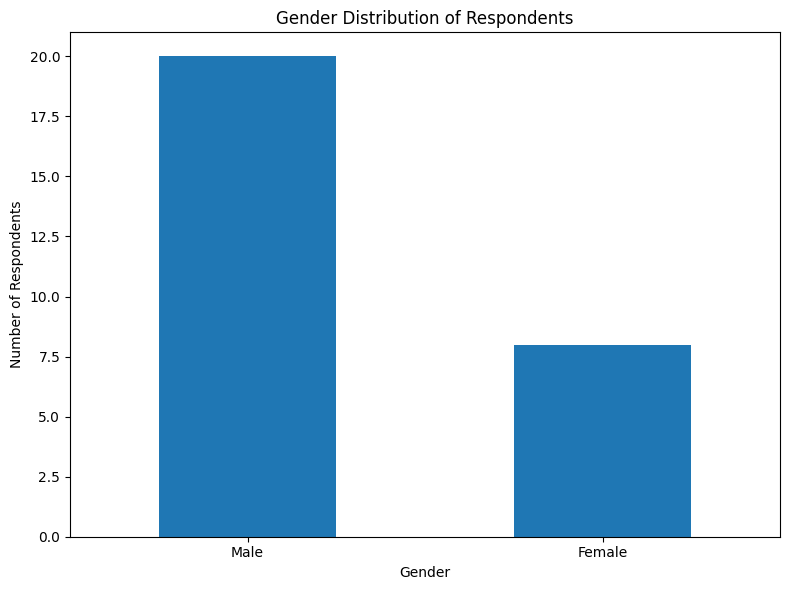

In [22]:
# Gender distribution

gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(8, 6))

gender_counts.plot(kind="bar")

plt.title("Gender Distribution of Respondents")
plt.xlabel("Gender")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    graph_folder / "01_gender_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

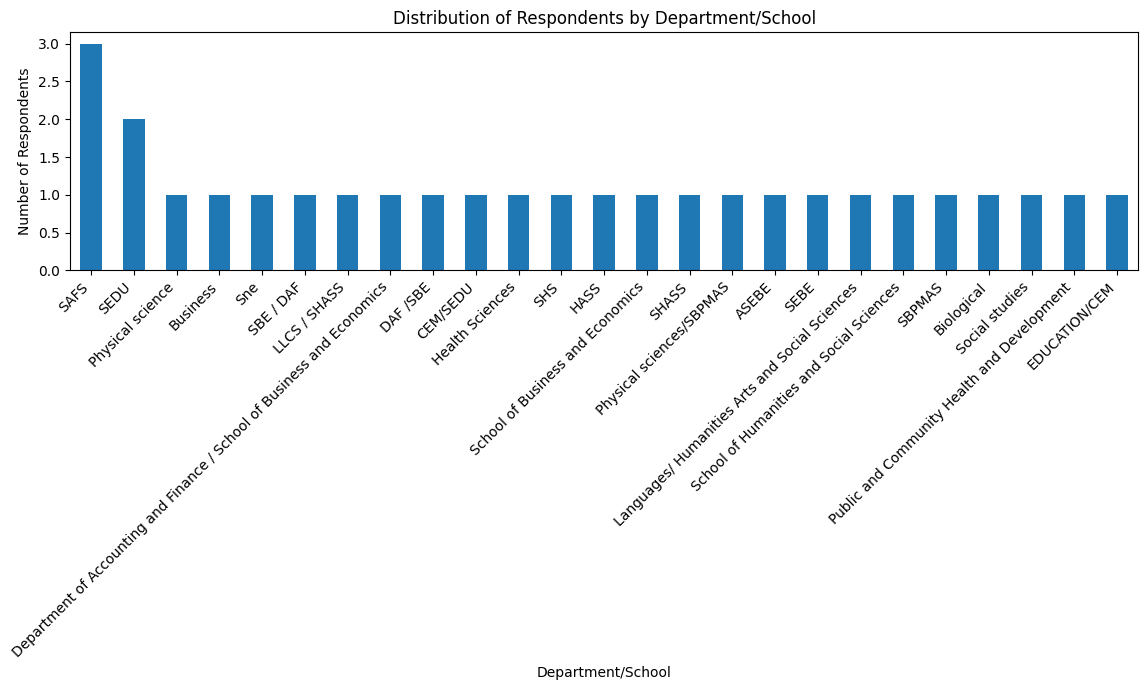

In [23]:
# Department/School distribution - VERTICAL

department_counts = (
    df["Department/School"]
    .value_counts()
)

plt.figure(figsize=(12, 7))

department_counts.plot(kind="bar")

plt.title("Distribution of Respondents by Department/School")
plt.xlabel("Department/School")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    graph_folder / "02_department_school_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

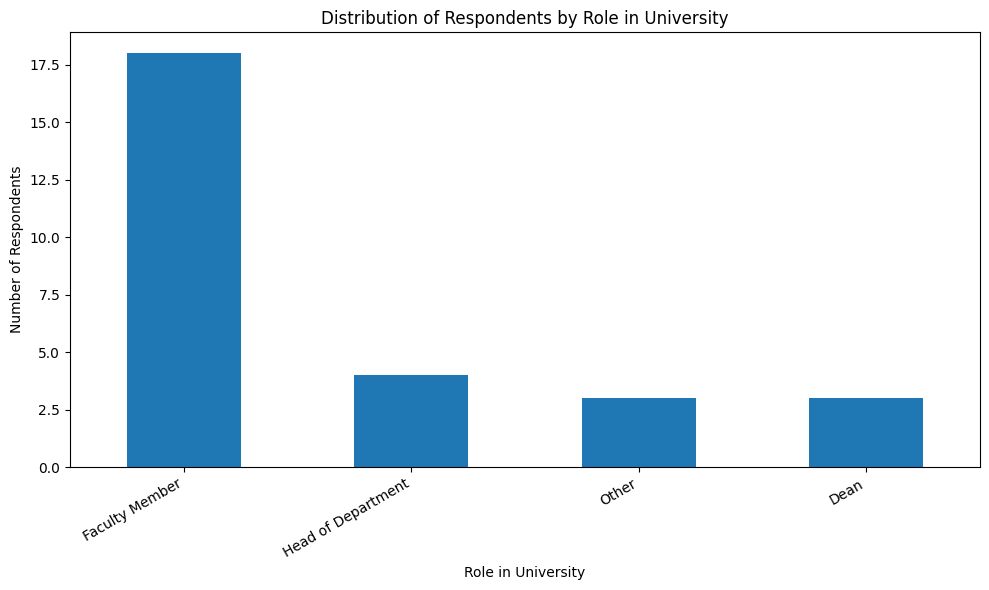

In [24]:
# Role in University distribution - VERTICAL

role_counts = (
    df["Role_in_University"]
    .value_counts()
)

plt.figure(figsize=(10, 6))

role_counts.plot(kind="bar")

plt.title("Distribution of Respondents by Role in University")
plt.xlabel("Role in University")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig(
    graph_folder / "03_role_in_university_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Distribution of Responses for Regulatory Questions

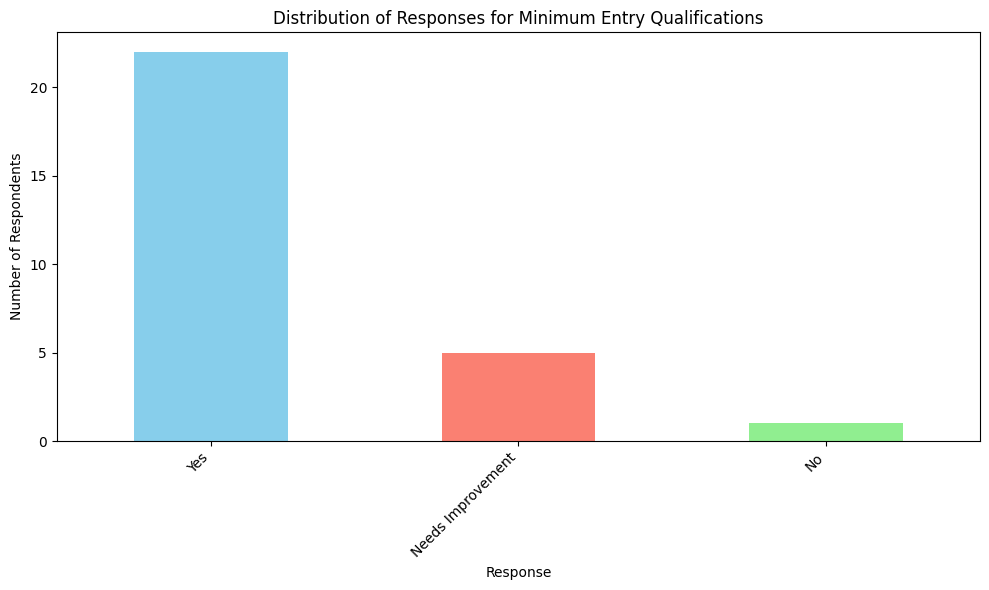

In [25]:
# Distribution for 'Minimum_entry_qualifications'

min_entry_qual_counts = df["Minimum_entry_qualifications"].value_counts()

plt.figure(figsize=(10, 6))

min_entry_qual_counts.plot(kind="bar", color=['skyblue', 'salmon', 'lightgreen'])

plt.title("Distribution of Responses for Minimum Entry Qualifications")
plt.xlabel("Response")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    graph_folder / "04_minimum_entry_qualifications_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

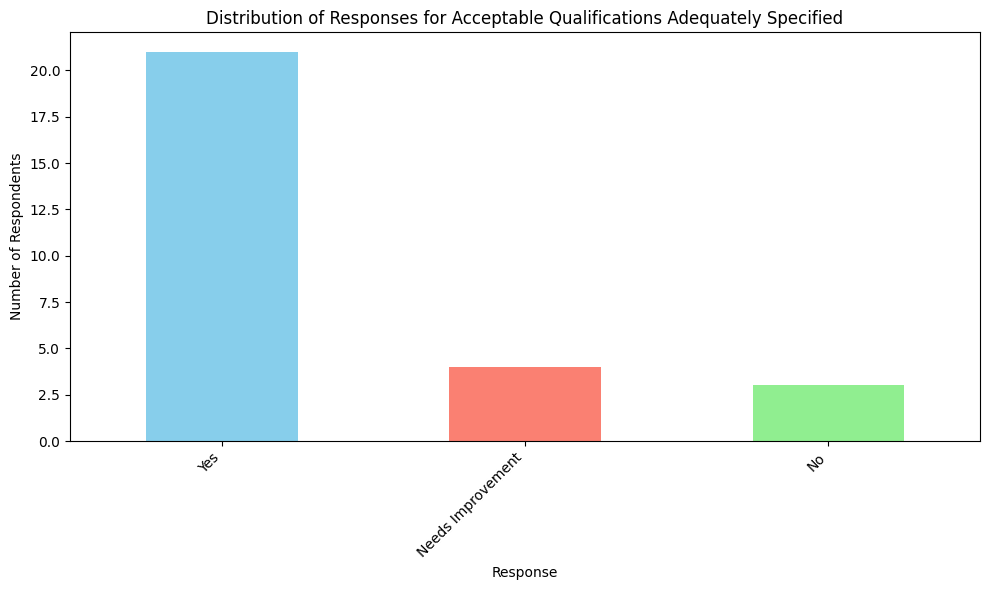

In [26]:
# Distribution for 'Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds'

acceptable_qual_counts = df["Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds"].value_counts()

plt.figure(figsize=(10, 6))

acceptable_qual_counts.plot(kind="bar", color=['skyblue', 'salmon', 'lightgreen'])

plt.title("Distribution of Responses for Acceptable Qualifications Adequately Specified")
plt.xlabel("Response")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    graph_folder / "05_acceptable_qualifications_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

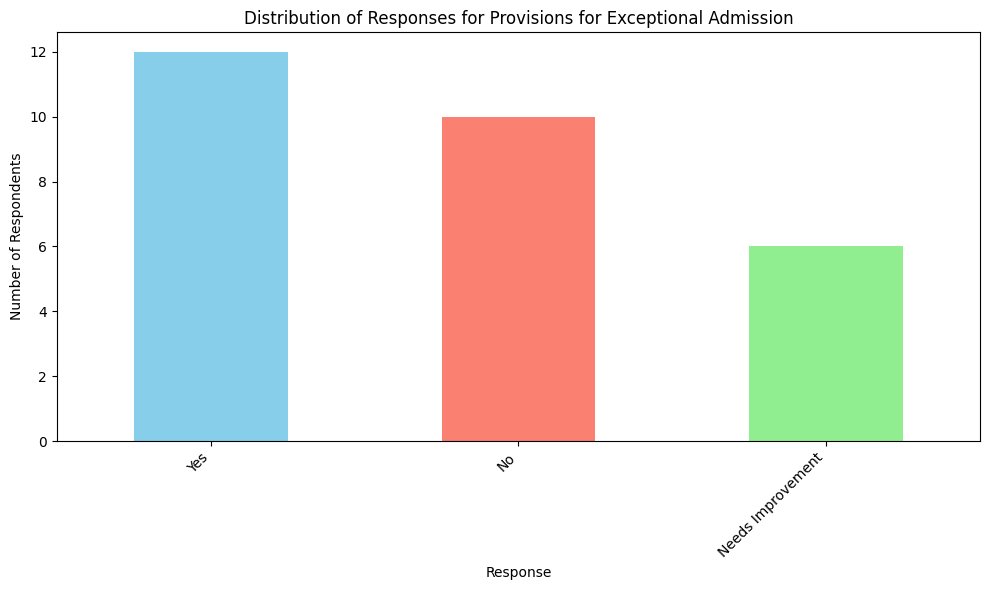

In [27]:
# Distribution for 'Provisions_exceptional_admission(if applicable)'

exceptional_admission_counts = df["Provisions_exceptional_admission(if applicable)"].value_counts()

plt.figure(figsize=(10, 6))

exceptional_admission_counts.plot(kind="bar", color=['skyblue', 'salmon', 'lightgreen'])

plt.title("Distribution of Responses for Provisions for Exceptional Admission")
plt.xlabel("Response")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    graph_folder / "06_provisions_exceptional_admission_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

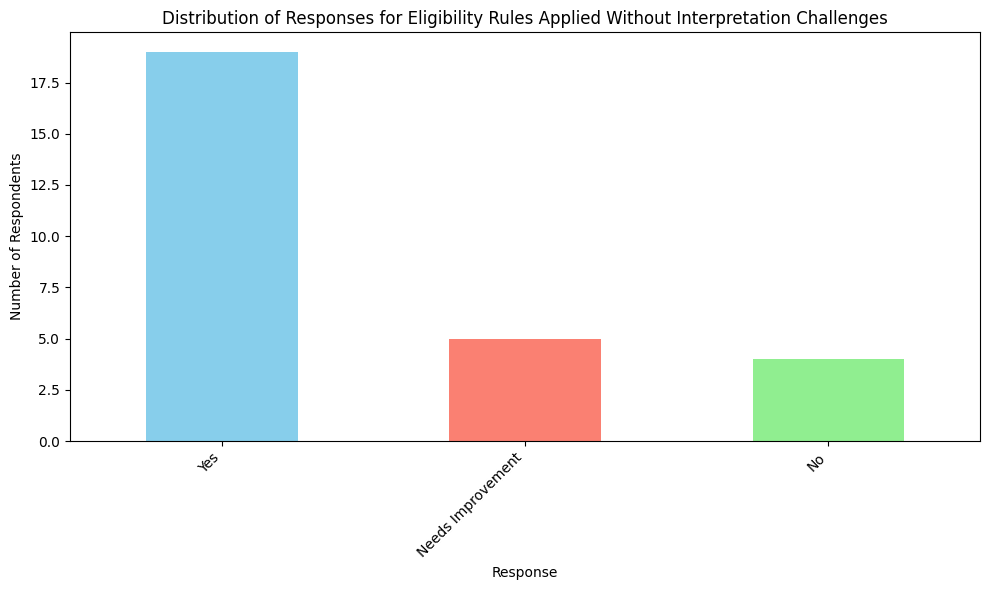

In [28]:
# Distribution for 'Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level'

eligibility_rules_counts = df["Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level"].value_counts()

plt.figure(figsize=(10, 6))

eligibility_rules_counts.plot(kind="bar", color=['skyblue', 'salmon', 'lightgreen'])

plt.title("Distribution of Responses for Eligibility Rules Applied Without Interpretation Challenges")
plt.xlabel("Response")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    graph_folder / "07_eligibility_rules_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

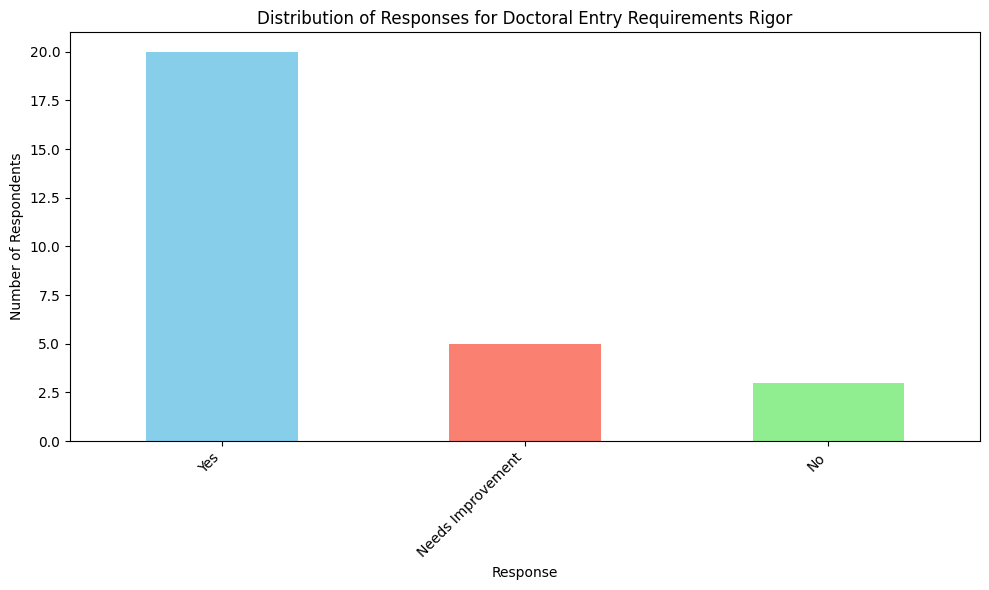

In [29]:
# Distribution for 'Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks'

doctoral_entry_counts = df["Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks"].value_counts()

plt.figure(figsize=(10, 6))

doctoral_entry_counts.plot(kind="bar", color=['skyblue', 'salmon', 'lightgreen'])

plt.title("Distribution of Responses for Doctoral Entry Requirements Rigor")
plt.xlabel("Response")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    graph_folder / "08_doctoral_entry_requirements_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

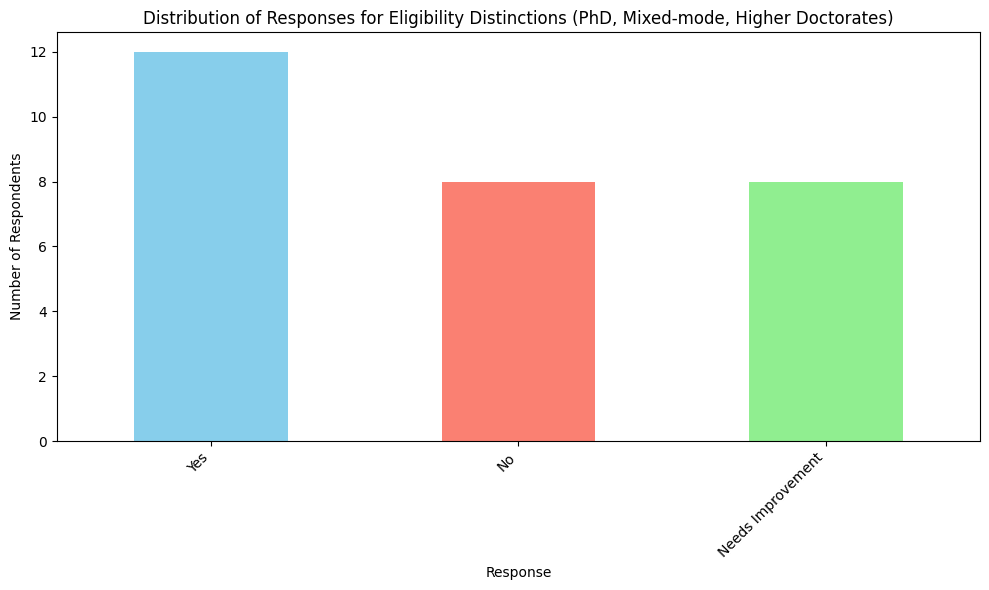

In [30]:
# Distribution for 'Eligibility_distinctions_btwn_PhD_research_mixed-modePhD&higher_doctorates_clearlydefined'

eligibility_distinctions_counts = df["Eligibility_distinctions_btwn_PhD_research_mixed-modePhD&higher_doctorates_clearlydefined"].value_counts()

plt.figure(figsize=(10, 6))

eligibility_distinctions_counts.plot(kind="bar", color=['skyblue', 'salmon', 'lightgreen'])

plt.title("Distribution of Responses for Eligibility Distinctions (PhD, Mixed-mode, Higher Doctorates)")
plt.xlabel("Response")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    graph_folder / "09_eligibility_distinctions_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Summary Table for Regulatory Questions

In [31]:
display(regulatory_summary)

,Yes_Count,No_Count,Needs_Improvement_Count,Yes_%,No_%,Needs_Improvement_%
Minimum_entry_qualifications,22,1,5,78.57,3.57,17.86
Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds,21,3,4,75.00,10.71,14.29
Provisions_exceptional_admission(if applicable),12,10,6,42.86,35.71,21.43
Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level,19,4,5,67.86,14.29,17.86
Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks,20,3,5,71.43,10.71,17.86
Eligibility_distinctions_btwn_PhD_research_mixed-modePhD&higher_doctorates_clearlydefined,12,8,8,42.86,28.57,28.57
Progression_routes_from_Master’s_Doctoral_study_clearly_articulated,21,4,3,75.00,14.29,10.71
"Programme_structure(coursework, research, or mixed mode)_implemented",19,4,5,67.86,14.29,17.86
Creditload_duration_research_prescribed_appropriate_awardlevel,16,8,4,57.14,28.57,14.29
Transitions_btwn_coursework&researchphases_guided_regulations,18,2,8,64.29,7.14,28.57


### Relationship between Gender and Minimum Entry Qualifications

In [32]:
# Create a cross-tabulation of Gender and Minimum_entry_qualifications
gender_min_entry_crosstab = pd.crosstab(df['Gender'], df['Minimum_entry_qualifications'])
display(gender_min_entry_crosstab)

Minimum_entry_qualifications,Needs Improvement,No,Yes
Gender,,,
Female,1,0,7
Male,4,1,15


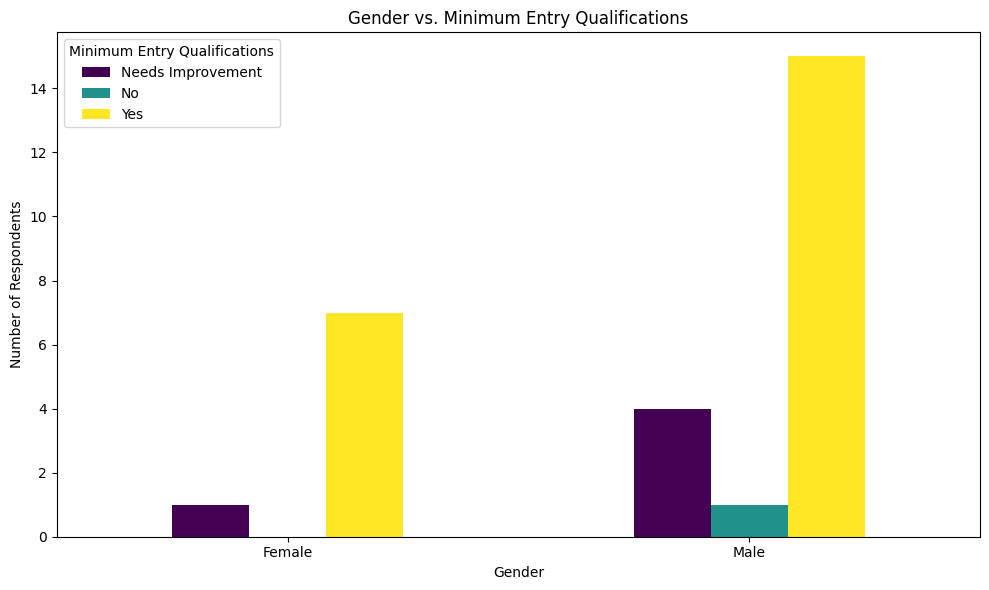

In [33]:
# Plotting the grouped bar chart for Gender and Minimum_entry_qualifications

gender_min_entry_crosstab.plot(kind='bar', figsize=(10, 6), colormap='viridis')

plt.title('Gender vs. Minimum Entry Qualifications')
plt.xlabel('Gender')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Minimum Entry Qualifications')

plt.tight_layout()

plt.savefig(
    graph_folder / "10_gender_vs_min_entry_qualifications.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Role in University and Doctoral Entry Requirements Rigor

In [34]:
# Create a cross-tabulation of Role_in_University and Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks
role_doctoral_entry_crosstab = pd.crosstab(df['Role_in_University'], df['Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks'])
display(role_doctoral_entry_crosstab)

Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks,Needs Improvement,No,Yes
Role_in_University,,,
Dean,1,0,2
Faculty Member,3,2,13
Head of Department,0,0,4
Other,1,1,1


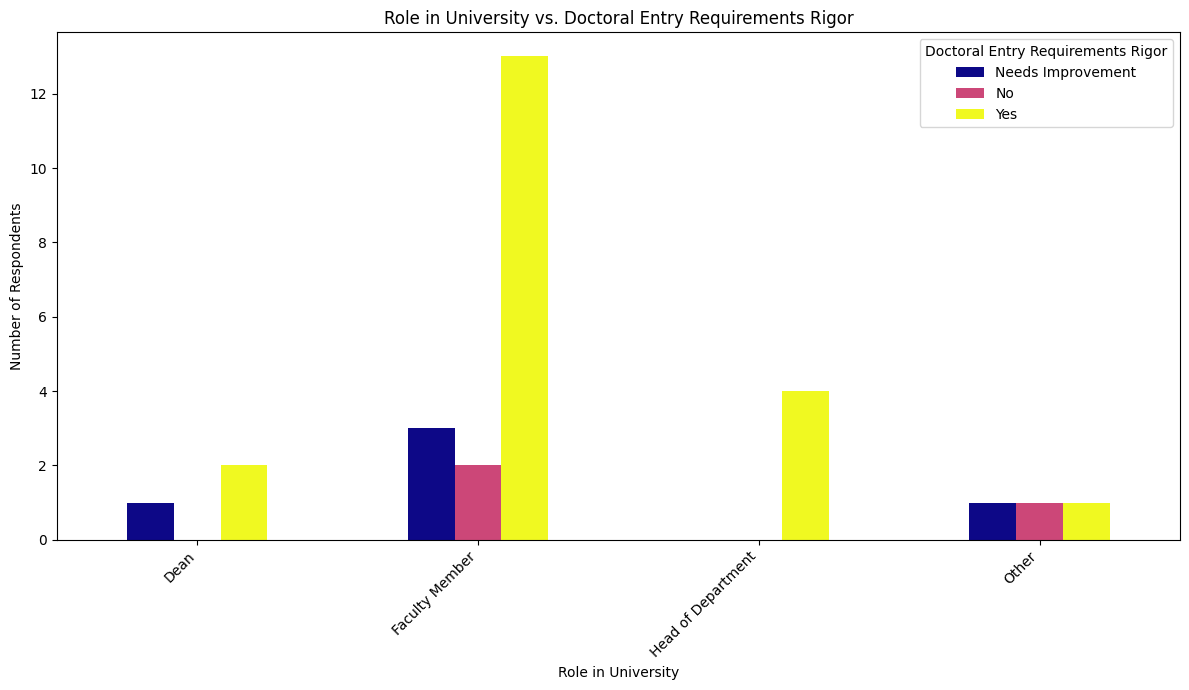

In [35]:
# Plotting the grouped bar chart for Role_in_University and Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks

role_doctoral_entry_crosstab.plot(kind='bar', figsize=(12, 7), colormap='plasma')

plt.title('Role in University vs. Doctoral Entry Requirements Rigor')
plt.xlabel('Role in University')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Doctoral Entry Requirements Rigor')

plt.tight_layout()

plt.savefig(
    graph_folder / "11_role_vs_doctoral_entry_requirements.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Role in University and Regulations Supporting Completion without Compromising Rigor

In [36]:
# Create a cross-tabulation of Role_in_University and Regulations_support_completion_without_compromising_academic_rigor
role_regulations_support_crosstab = pd.crosstab(df['Role_in_University'], df['Regulations_support_completion_without_compromising_academic_rigor'])
display(role_regulations_support_crosstab)

Regulations_support_completion_without_compromising_academic_rigor,Needs Improvement,No,Yes
Role_in_University,,,
Dean,0,2,1
Faculty Member,6,5,7
Head of Department,2,1,1
Other,1,1,1


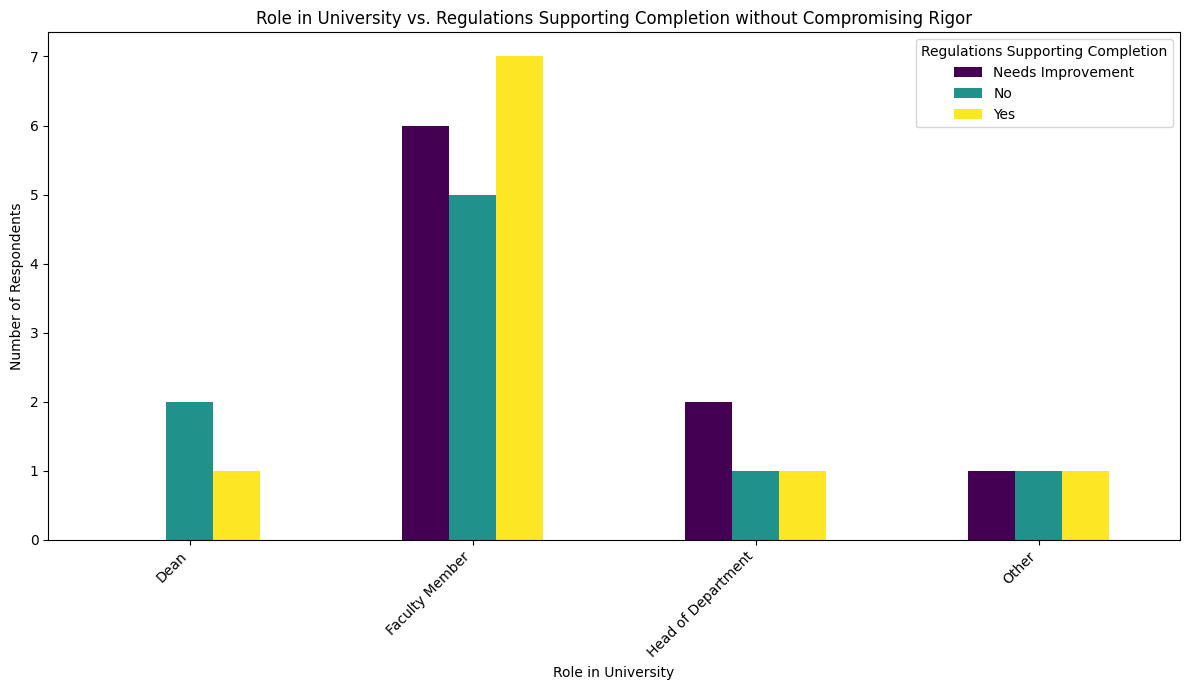

In [37]:
# Plotting the grouped bar chart for Role_in_University and Regulations_support_completion_without_compromising_academic_rigor

role_regulations_support_crosstab.plot(kind='bar', figsize=(12, 7), colormap='viridis')

plt.title('Role in University vs. Regulations Supporting Completion without Compromising Rigor')
plt.xlabel('Role in University')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Regulations Supporting Completion')

plt.tight_layout()

plt.savefig(
    graph_folder / "12_role_vs_regulations_support.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Role in University and Regulations Addressing Delays/Conflicting Reports

In [38]:
# Create a cross-tabulation of Role_in_University and Regulations_address_delays_non-responsiveness_conflicting_reports
role_delays_reports_crosstab = pd.crosstab(df['Role_in_University'], df['Regulations_address_delays_non-responsiveness_conflicting_reports'])
display(role_delays_reports_crosstab)

Regulations_address_delays_non-responsiveness_conflicting_reports,Needs Improvement,No,Yes
Role_in_University,,,
Dean,0,2,1
Faculty Member,4,5,9
Head of Department,1,1,2
Other,2,0,1


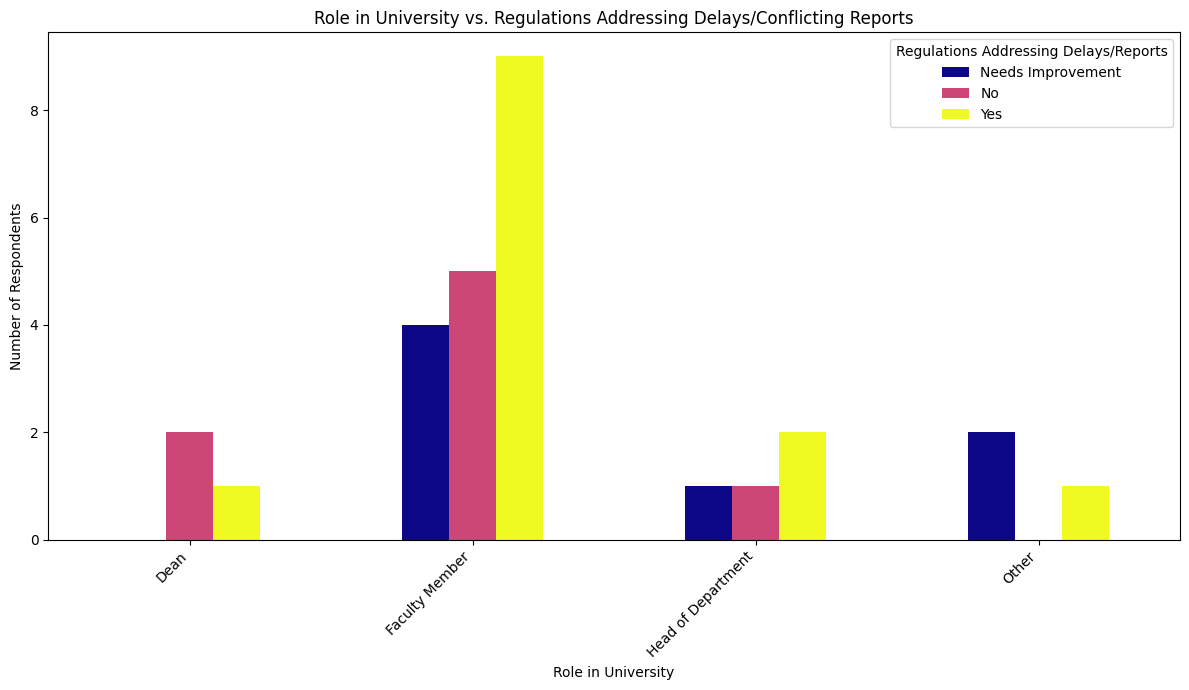

In [39]:
# Plotting the grouped bar chart for Role_in_University and Regulations_address_delays_non-responsiveness_conflicting_reports

role_delays_reports_crosstab.plot(kind='bar', figsize=(12, 7), colormap='plasma')

plt.title('Role in University vs. Regulations Addressing Delays/Conflicting Reports')
plt.xlabel('Role in University')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Regulations Addressing Delays/Reports')

plt.tight_layout()

plt.savefig(
    graph_folder / "13_role_vs_regulations_delays_reports.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Gender and Assessment & Examination Procedures Clarity

In [40]:
# Create a cross-tabulation of Gender and Assessment&examination_procedures_clearly_distinguished_for_coursework&researchprogrammes
gender_assessment_crosstab = pd.crosstab(df['Gender'], df['Assessment&examination_procedures_clearly_distinguished_for_coursework&researchprogrammes'])
display(gender_assessment_crosstab)

Assessment&examination_procedures_clearly_distinguished_for_coursework&researchprogrammes,Needs Improvement,No,Yes
Gender,,,
Female,0,0,8
Male,4,1,15


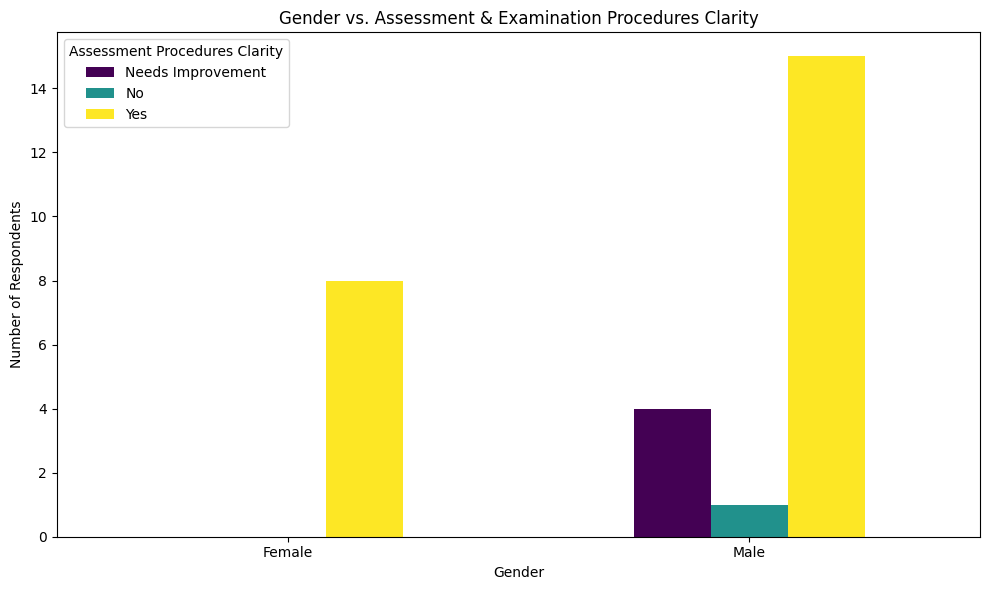

In [41]:
# Plotting the grouped bar chart for Gender and Assessment&examination_procedures_clearly_distinguished_for_coursework&researchprogrammes

gender_assessment_crosstab.plot(kind='bar', figsize=(10, 6), colormap='viridis')

plt.title('Gender vs. Assessment & Examination Procedures Clarity')
plt.xlabel('Gender')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Assessment Procedures Clarity')

plt.tight_layout()

plt.savefig(
    graph_folder / "14_gender_vs_assessment_procedures.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Gender and PhD Submission & Examination Processes

In [42]:
# Create a cross-tabulation of Gender and Submission_examination_PhD_processes
gender_phd_submission_crosstab = pd.crosstab(df['Gender'], df['Submission_examination_PhD_processes'])
display(gender_phd_submission_crosstab)

Submission_examination_PhD_processes,Needs Improvement,No,Yes
Gender,,,
Female,0,2,6
Male,3,9,8


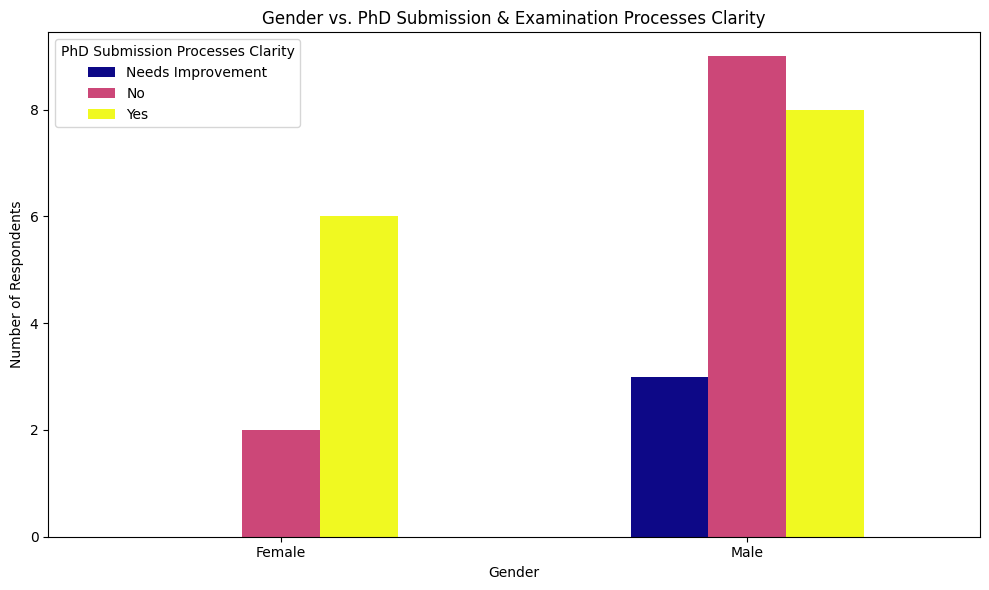

In [43]:
# Plotting the grouped bar chart for Gender and Submission_examination_PhD_processes

gender_phd_submission_crosstab.plot(kind='bar', figsize=(10, 6), colormap='plasma')

plt.title('Gender vs. PhD Submission & Examination Processes Clarity')
plt.xlabel('Gender')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=0)
plt.legend(title='PhD Submission Processes Clarity')

plt.tight_layout()

plt.savefig(
    graph_folder / "15_gender_vs_phd_submission_processes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Gender and Programme Structure Implementation

In [44]:
# Create a cross-tabulation of Gender and Programme_structure(coursework, research, or mixed mode)_implemented
gender_programme_structure_crosstab = pd.crosstab(df['Gender'], df['Programme_structure(coursework, research, or mixed mode)_implemented'])
display(gender_programme_structure_crosstab)

"Programme_structure(coursework, research, or mixed mode)_implemented",Needs Improvement,No,Yes
Gender,,,
Female,1,1,6
Male,4,3,13


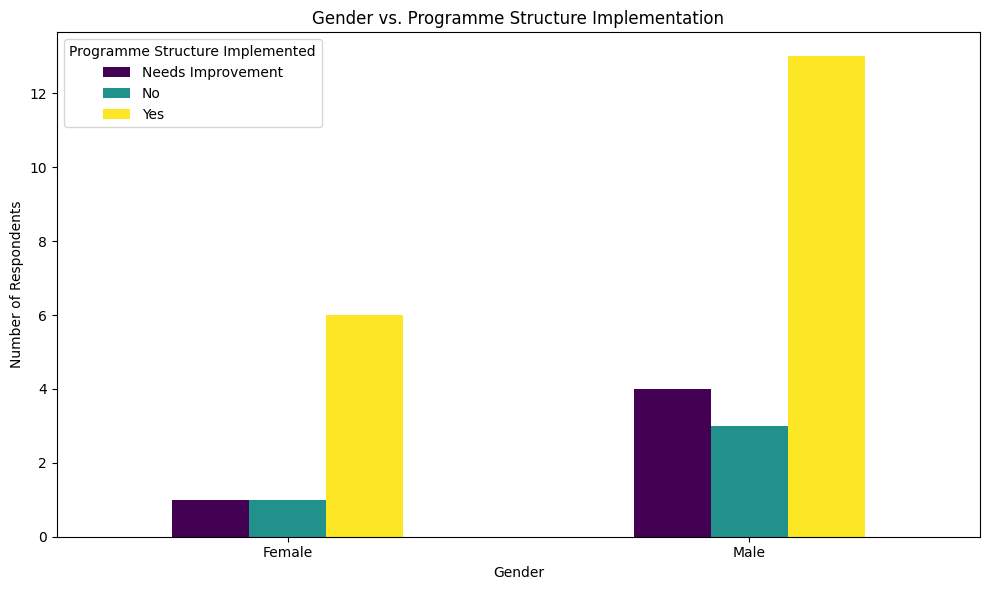

In [45]:
# Plotting the grouped bar chart for Gender and Programme_structure(coursework, research, or mixed mode)_implemented

gender_programme_structure_crosstab.plot(kind='bar', figsize=(10, 6), colormap='viridis')

plt.title('Gender vs. Programme Structure Implementation')
plt.xlabel('Gender')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Programme Structure Implemented')

plt.tight_layout()

plt.savefig(
    graph_folder / "16_gender_vs_programme_structure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Gender and Progression Routes from Master’s to Doctoral Study

In [46]:
# Create a cross-tabulation of Gender and Progression_routes_from_Master’s_Doctoral_study_clearly_articulated
gender_progression_routes_crosstab = pd.crosstab(df['Gender'], df['Progression_routes_from_Master’s_Doctoral_study_clearly_articulated'])
display(gender_progression_routes_crosstab)

Progression_routes_from_Master’s_Doctoral_study_clearly_articulated,Needs Improvement,No,Yes
Gender,,,
Female,1,0,7
Male,2,4,14


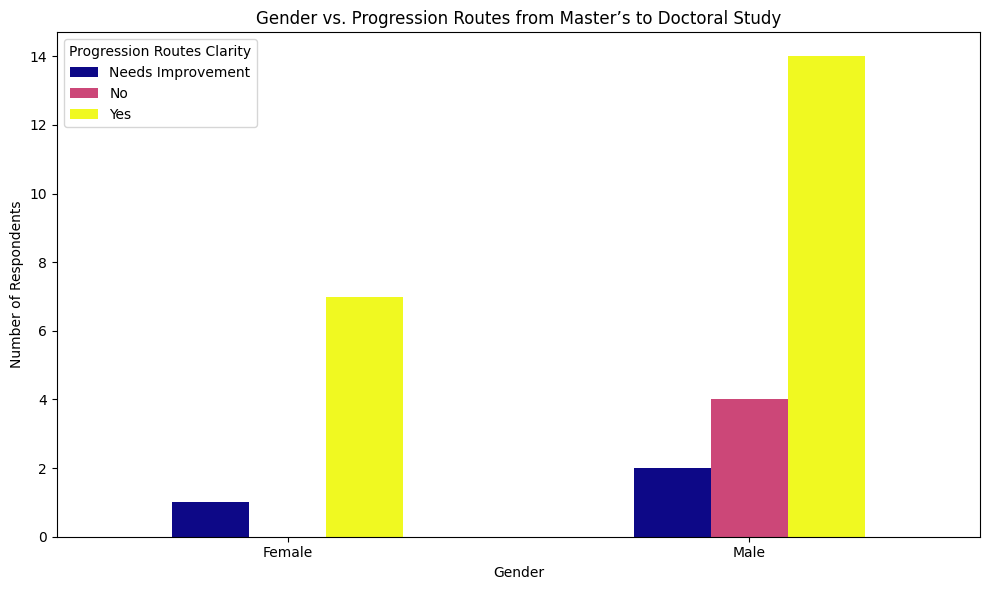

In [47]:
# Plotting the grouped bar chart for Gender and Progression_routes_from_Master’s_Doctoral_study_clearly_articulated

gender_progression_routes_crosstab.plot(kind='bar', figsize=(10, 6), colormap='plasma')

plt.title('Gender vs. Progression Routes from Master’s to Doctoral Study')
plt.xlabel('Gender')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Progression Routes Clarity')

plt.tight_layout()

plt.savefig(
    graph_folder / "17_gender_vs_progression_routes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Role in University and Eligibility Rules Application

In [48]:
# Create a cross-tabulation of Role_in_University and Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level
role_eligibility_rules_crosstab = pd.crosstab(df['Role_in_University'], df['Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level'])
display(role_eligibility_rules_crosstab)

Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level,Needs Improvement,No,Yes
Role_in_University,,,
Dean,1,0,2
Faculty Member,1,3,14
Head of Department,2,0,2
Other,1,1,1


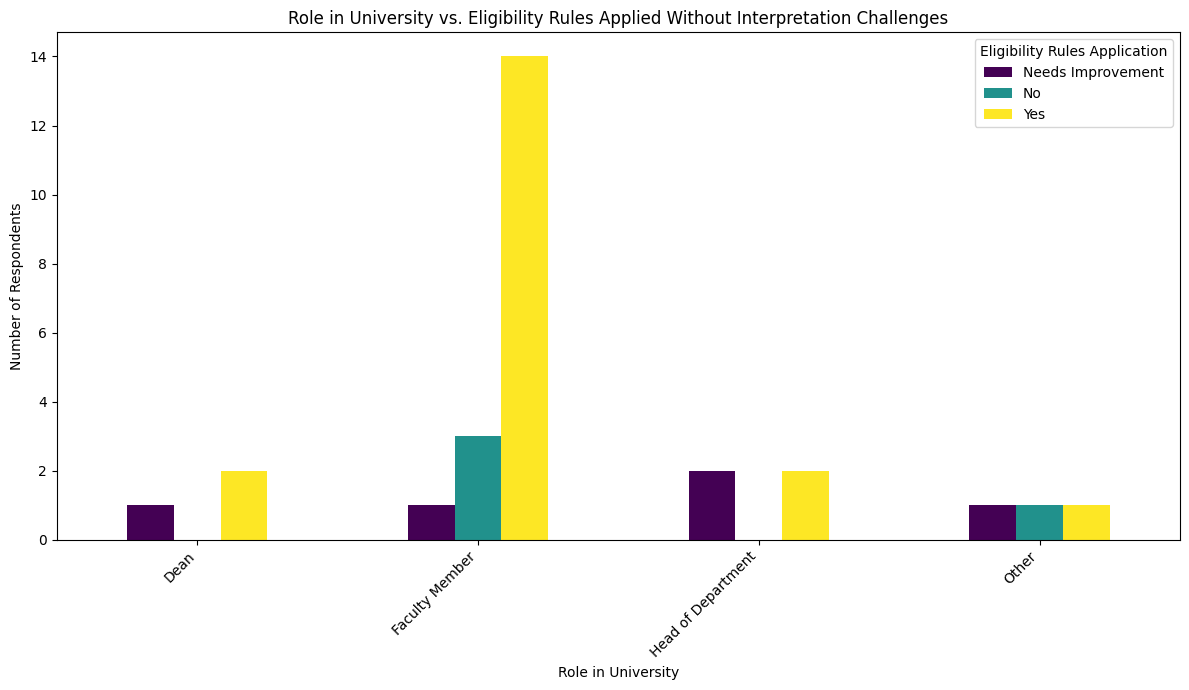

In [49]:
# Plotting the grouped bar chart for Role_in_University and Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level

role_eligibility_rules_crosstab.plot(kind='bar', figsize=(12, 7), colormap='viridis')

plt.title('Role in University vs. Eligibility Rules Applied Without Interpretation Challenges')
plt.xlabel('Role in University')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Eligibility Rules Application')

plt.tight_layout()

plt.savefig(
    graph_folder / "18_role_vs_eligibility_rules.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Faculty and Minimum Entry Qualifications

In [52]:
# Create a cross-tabulation of Department/School and Minimum_entry_qualifications
faculty_min_entry_crosstab = pd.crosstab(df['Department/School'], df['Minimum_entry_qualifications'])
display(faculty_min_entry_crosstab)

Minimum_entry_qualifications,Needs Improvement,No,Yes
Department/School,,,
ASEBE,0,0,1
Biological,0,0,1
Business,0,0,1
CEM/SEDU,1,0,0
DAF /SBE,0,0,1
Department of Accounting and Finance / School of Business and Economics,0,0,1
EDUCATION/CEM,0,1,0
HASS,0,0,1
Health Sciences,0,0,1


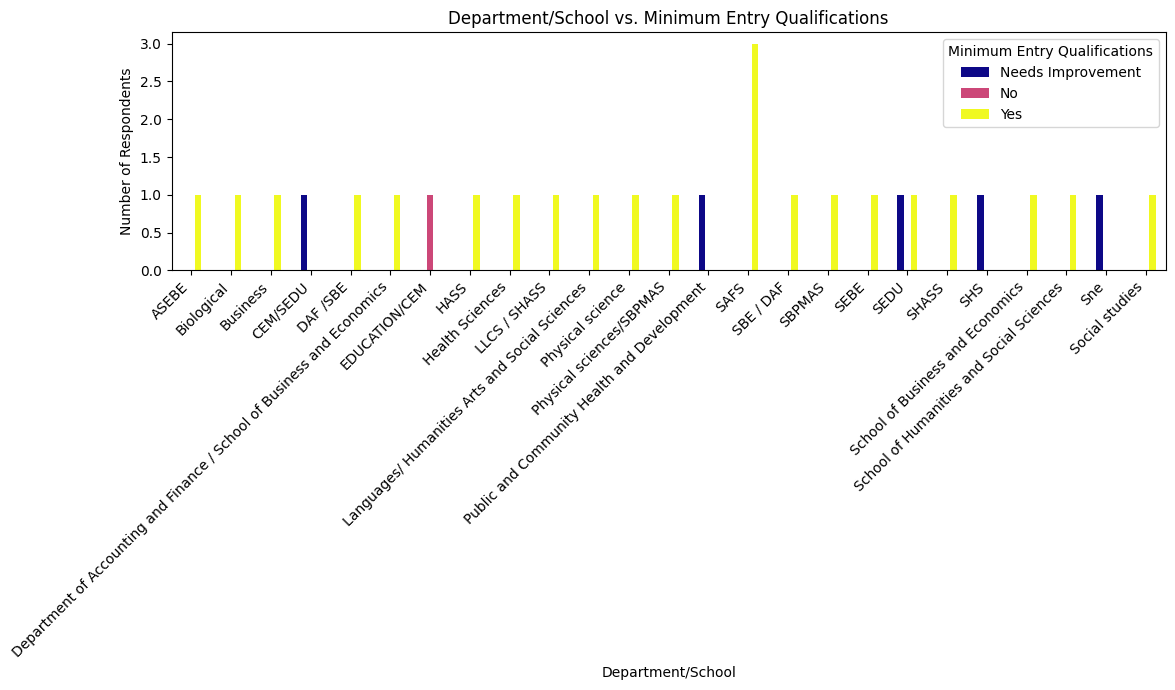

In [53]:
# Plotting the grouped bar chart for Department/School and Minimum_entry_qualifications

faculty_min_entry_crosstab.plot(kind='bar', figsize=(12, 7), colormap='plasma')

plt.title('Department/School vs. Minimum Entry Qualifications')
plt.xlabel('Department/School')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Minimum Entry Qualifications')

plt.tight_layout()

plt.savefig(
    graph_folder / "19_department_school_vs_min_entry_qualifications.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Gender and Doctoral Entry Requirements Rigor

In [54]:
# Create a cross-tabulation of Gender and Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks
gender_doctoral_entry_crosstab = pd.crosstab(df['Gender'], df['Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks'])
display(gender_doctoral_entry_crosstab)

Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks,Needs Improvement,No,Yes
Gender,,,
Female,0,1,7
Male,5,2,13


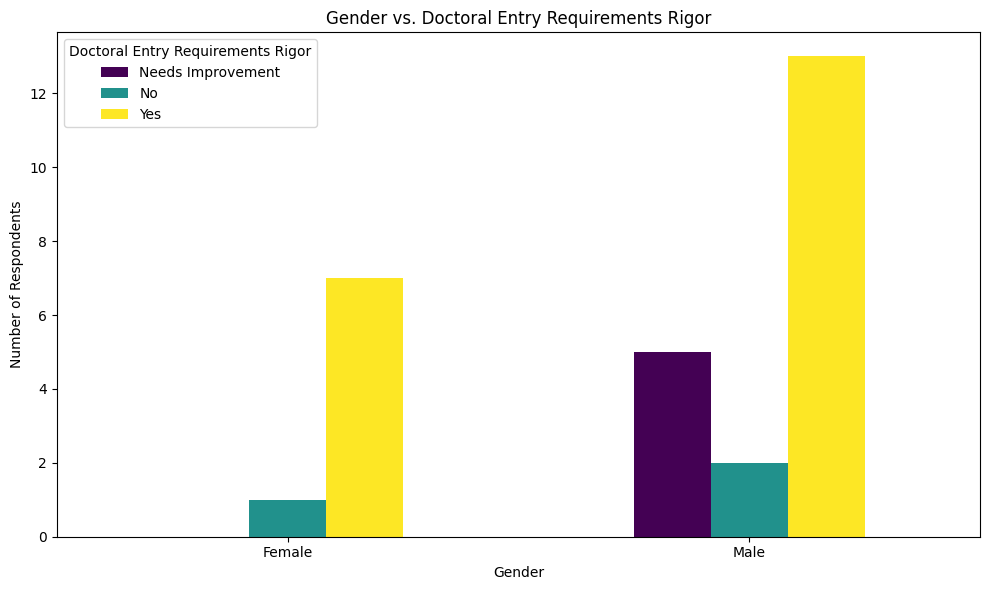

In [55]:
# Plotting the grouped bar chart for Gender and Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks

gender_doctoral_entry_crosstab.plot(kind='bar', figsize=(10, 6), colormap='viridis')

plt.title('Gender vs. Doctoral Entry Requirements Rigor')
plt.xlabel('Gender')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Doctoral Entry Requirements Rigor')

plt.tight_layout()

plt.savefig(
    graph_folder / "20_gender_vs_doctoral_entry_rigor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Role in University and Credit Load/Duration of Research

In [56]:
# Create a cross-tabulation of Role_in_University and Creditload_duration_research_prescribed_appropriate_awardlevel
role_creditload_crosstab = pd.crosstab(df['Role_in_University'], df['Creditload_duration_research_prescribed_appropriate_awardlevel'])
display(role_creditload_crosstab)

Creditload_duration_research_prescribed_appropriate_awardlevel,Needs Improvement,No,Yes
Role_in_University,,,
Dean,1,1,1
Faculty Member,1,5,12
Head of Department,1,1,2
Other,1,1,1


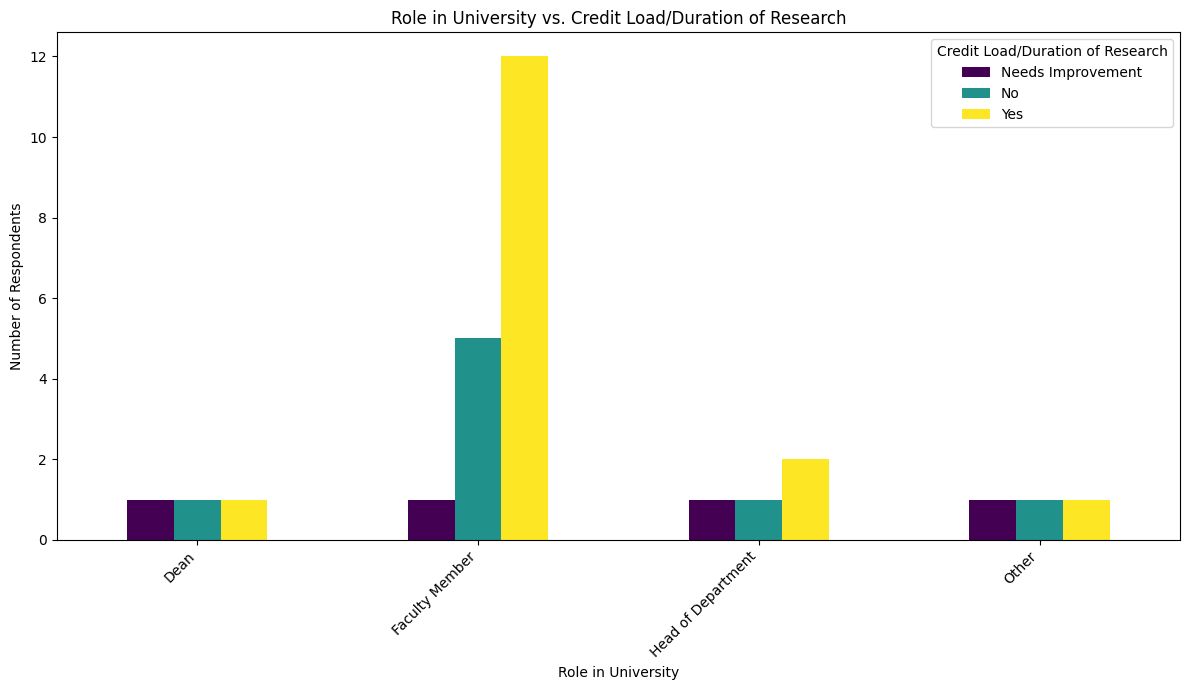

In [57]:
# Plotting the grouped bar chart for Role_in_University and Creditload_duration_research_prescribed_appropriate_awardlevel

role_creditload_crosstab.plot(kind='bar', figsize=(12, 7), colormap='viridis')

plt.title('Role in University vs. Credit Load/Duration of Research')
plt.xlabel('Role in University')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Credit Load/Duration of Research')

plt.tight_layout()

plt.savefig(
    graph_folder / "21_role_vs_creditload_duration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Role in University and Acceptable Qualifications Specification

In [58]:
# Create a cross-tabulation of Role_in_University and Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds
role_acceptable_qual_crosstab = pd.crosstab(df['Role_in_University'], df['Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds'])
display(role_acceptable_qual_crosstab)

Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds,Needs Improvement,No,Yes
Role_in_University,,,
Dean,1,0,2
Faculty Member,2,3,13
Head of Department,0,0,4
Other,1,0,2


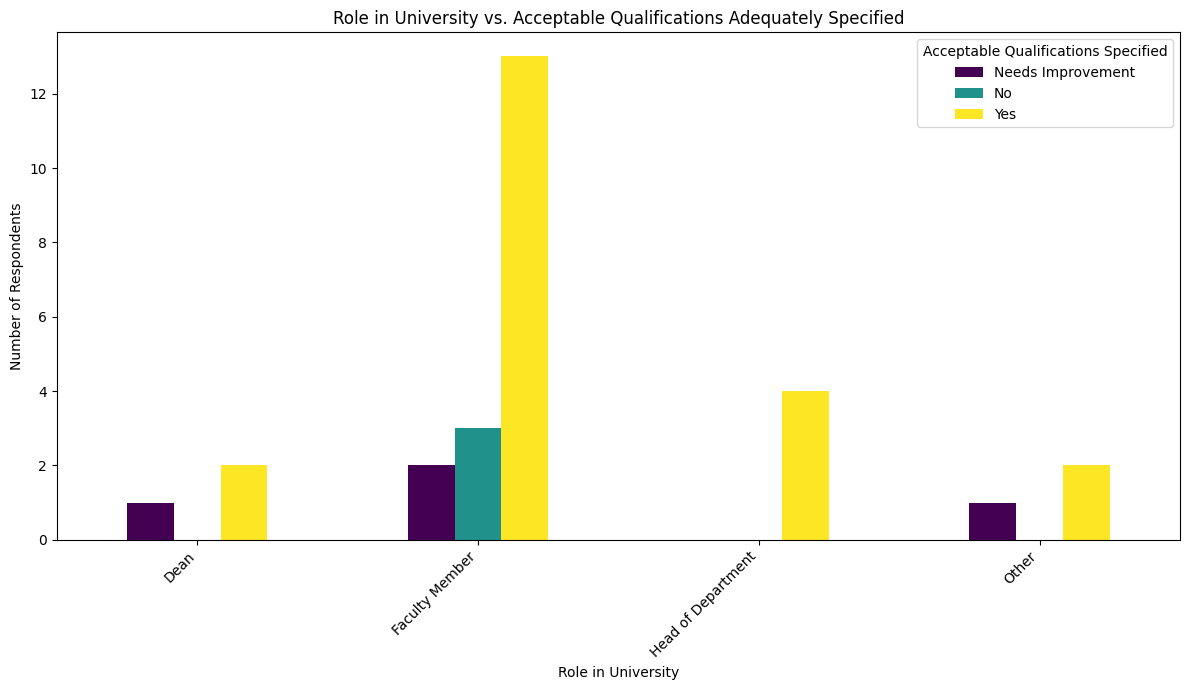

In [59]:
# Plotting the grouped bar chart for Role_in_University and Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds

role_acceptable_qual_crosstab.plot(kind='bar', figsize=(12, 7), colormap='viridis')

plt.title('Role in University vs. Acceptable Qualifications Adequately Specified')
plt.xlabel('Role in University')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Acceptable Qualifications Specified')

plt.tight_layout()

plt.savefig(
    graph_folder / "22_role_vs_acceptable_qualifications.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship between Role in University and Criteria for Supervisor Appointment

In [62]:
# Create a cross-tabulation of Role_in_University and criteria_for_supervisor_appointment_defined&consistently_applied
role_resources_crosstab = pd.crosstab(df['Role_in_University'], df['criteria_for_supervisor_appointment_defined&consistently_applied'])
display(role_resources_crosstab)

criteria_for_supervisor_appointment_defined&consistently_applied,Needs Improvement,No,Yes
Role_in_University,,,
Dean,1,1,1
Faculty Member,7,4,7
Head of Department,1,0,3
Other,1,0,2


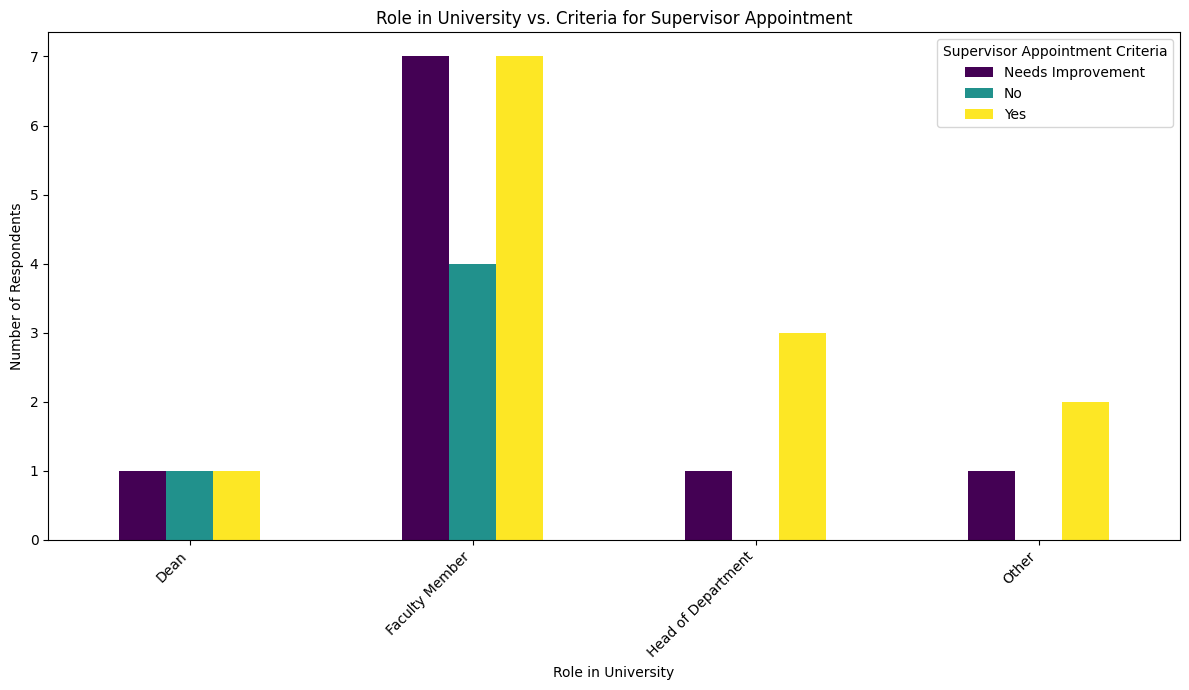

In [63]:
# Plotting the grouped bar chart for Role_in_University and criteria_for_supervisor_appointment_defined&consistently_applied

role_resources_crosstab.plot(kind='bar', figsize=(12, 7), colormap='viridis')

plt.title('Role in University vs. Criteria for Supervisor Appointment')
plt.xlabel('Role in University')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Supervisor Appointment Criteria')

plt.tight_layout()

plt.savefig(
    graph_folder / "24_role_vs_supervisor_criteria.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Chi-square Tests for Association

To determine if the observed relationships between categorical variables are statistically significant, we will use the Chi-square test of independence. This test assesses whether there is a significant association between two categorical variables. A low p-value (typically < 0.05) indicates that the variables are statistically associated.

We will define a helper function to streamline the process and interpret the results.

In [78]:
from scipy.stats import chi2_contingency

def perform_chi_square_test(crosstab, var1_name, var2_name):
    """
    Performs a Chi-square test of independence on a given cross-tabulation
    and prints the results.
    """
    print(f"\n--- Chi-square Test for {var1_name} vs. {var2_name} ---")
    stat, p, dof, expected = chi2_contingency(crosstab)

    print(f"Chi-square Statistic: {stat:.4f}")
    print(f"P-value: {p:.4f}")
    print(f"Degrees of Freedom: {dof}")

    alpha = 0.05
    if p < alpha:
        print(f"Interpretation: Since the p-value ({p:.4f}) is less than {alpha}, "
              f"we reject the null hypothesis. There is a statistically significant association "
              f"between {var1_name} and {var2_name}.")
    else:
        print(f"Interpretation: Since the p-value ({p:.4f}) is greater than or equal to {alpha}, "
              f"we fail to reject the null hypothesis. There is no statistically significant association "
              f"between {var1_name} and {var2_name}.")
    print("---------------------------------------------------")

### 1. Gender vs. Minimum Entry Qualifications

In [79]:
# Using the previously created cross-tabulation
perform_chi_square_test(gender_min_entry_crosstab, 'Gender', 'Minimum_entry_qualifications')


--- Chi-square Test for Gender vs. Minimum_entry_qualifications ---
Chi-square Statistic: 0.6936
P-value: 0.7069
Degrees of Freedom: 2
Interpretation: Since the p-value (0.7069) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Gender and Minimum_entry_qualifications.
---------------------------------------------------


### 2. Role in University vs. Doctoral Entry Requirements Rigor

In [80]:
# Using the previously created cross-tabulation
perform_chi_square_test(role_doctoral_entry_crosstab, 'Role_in_University', 'Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks')


--- Chi-square Test for Role_in_University vs. Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks ---
Chi-square Statistic: 4.7963
P-value: 0.5702
Degrees of Freedom: 6
Interpretation: Since the p-value (0.5702) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Role_in_University and Doctoral_entry_requirements_sufficiently_rigorous_aligned_benchmarks.
---------------------------------------------------


### 3. Role in University vs. Regulations Supporting Completion without Compromising Rigor

In [81]:
# Using the previously created cross-tabulation
perform_chi_square_test(role_regulations_support_crosstab, 'Role_in_University', 'Regulations_support_completion_without_compromising_academic_rigor')


--- Chi-square Test for Role_in_University vs. Regulations_support_completion_without_compromising_academic_rigor ---
Chi-square Statistic: 2.8432
P-value: 0.8283
Degrees of Freedom: 6
Interpretation: Since the p-value (0.8283) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Role_in_University and Regulations_support_completion_without_compromising_academic_rigor.
---------------------------------------------------


### 4. Role in University vs. Regulations Addressing Delays/Conflicting Reports

In [82]:
# Using the previously created cross-tabulation
perform_chi_square_test(role_delays_reports_crosstab, 'Role_in_University', 'Regulations_address_delays_non-responsiveness_conflicting_reports')


--- Chi-square Test for Role_in_University vs. Regulations_address_delays_non-responsiveness_conflicting_reports ---
Chi-square Statistic: 5.5737
P-value: 0.4726
Degrees of Freedom: 6
Interpretation: Since the p-value (0.4726) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Role_in_University and Regulations_address_delays_non-responsiveness_conflicting_reports.
---------------------------------------------------


### 5. Gender vs. Assessment & Examination Procedures Clarity

In [83]:
# Using the previously created cross-tabulation
perform_chi_square_test(gender_assessment_crosstab, 'Gender', 'Assessment&examination_procedures_clearly_distinguished_for_coursework&researchprogrammes')


--- Chi-square Test for Gender vs. Assessment&examination_procedures_clearly_distinguished_for_coursework&researchprogrammes ---
Chi-square Statistic: 2.4348
P-value: 0.2960
Degrees of Freedom: 2
Interpretation: Since the p-value (0.2960) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Gender and Assessment&examination_procedures_clearly_distinguished_for_coursework&researchprogrammes.
---------------------------------------------------


### 6. Gender vs. PhD Submission & Examination Processes

In [84]:
# Using the previously created cross-tabulation
perform_chi_square_test(gender_phd_submission_crosstab, 'Gender', 'Submission_examination_PhD_processes')


--- Chi-square Test for Gender vs. Submission_examination_PhD_processes ---
Chi-square Statistic: 3.1818
P-value: 0.2037
Degrees of Freedom: 2
Interpretation: Since the p-value (0.2037) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Gender and Submission_examination_PhD_processes.
---------------------------------------------------


### 7. Gender vs. Programme Structure Implementation

In [85]:
# Using the previously created cross-tabulation
perform_chi_square_test(gender_programme_structure_crosstab, 'Gender', 'Programme_structure(coursework, research, or mixed mode)_implemented')


--- Chi-square Test for Gender vs. Programme_structure(coursework, research, or mixed mode)_implemented ---
Chi-square Statistic: 0.2892
P-value: 0.8654
Degrees of Freedom: 2
Interpretation: Since the p-value (0.8654) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Gender and Programme_structure(coursework, research, or mixed mode)_implemented.
---------------------------------------------------


### 8. Gender vs. Progression Routes from Master’s to Doctoral Study

In [86]:
# Using the previously created cross-tabulation
perform_chi_square_test(gender_progression_routes_crosstab, 'Gender', 'Progression_routes_from_Master’s_Doctoral_study_clearly_articulated')


--- Chi-square Test for Gender vs. Progression_routes_from_Master’s_Doctoral_study_clearly_articulated ---
Chi-square Statistic: 1.8667
P-value: 0.3932
Degrees of Freedom: 2
Interpretation: Since the p-value (0.3932) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Gender and Progression_routes_from_Master’s_Doctoral_study_clearly_articulated.
---------------------------------------------------


### 9. Role in University vs. Eligibility Rules Application

In [87]:
# Using the previously created cross-tabulation
perform_chi_square_test(role_eligibility_rules_crosstab, 'Role_in_University', 'Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level')


--- Chi-square Test for Role_in_University vs. Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level ---
Chi-square Statistic: 7.4544
P-value: 0.2809
Degrees of Freedom: 6
Interpretation: Since the p-value (0.2809) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Role_in_University and Eligibility_rules_applied_without_interpretation challenges_faculty/departmental_level.
---------------------------------------------------


### 10. Department/School vs. Minimum Entry Qualifications

In [88]:
# Using the previously created cross-tabulation
perform_chi_square_test(faculty_min_entry_crosstab, 'Department/School', 'Minimum_entry_qualifications')


--- Chi-square Test for Department/School vs. Minimum_entry_qualifications ---
Chi-square Statistic: 52.5636
P-value: 0.3018
Degrees of Freedom: 48
Interpretation: Since the p-value (0.3018) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Department/School and Minimum_entry_qualifications.
---------------------------------------------------


### 11. Role in University vs. Credit Load/Duration of Research

In [89]:
# Using the previously created cross-tabulation
perform_chi_square_test(role_creditload_crosstab, 'Role_in_University', 'Creditload_duration_research_prescribed_appropriate_awardlevel')


--- Chi-square Test for Role_in_University vs. Creditload_duration_research_prescribed_appropriate_awardlevel ---
Chi-square Statistic: 3.7917
P-value: 0.7048
Degrees of Freedom: 6
Interpretation: Since the p-value (0.7048) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Role_in_University and Creditload_duration_research_prescribed_appropriate_awardlevel.
---------------------------------------------------


### 12. Role in University vs. Acceptable Qualifications Specification

In [90]:
# Using the previously created cross-tabulation
perform_chi_square_test(role_acceptable_qual_crosstab, 'Role_in_University', 'Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds')


--- Chi-square Test for Role_in_University vs. Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds ---
Chi-square Statistic: 4.2963
P-value: 0.6366
Degrees of Freedom: 6
Interpretation: Since the p-value (0.6366) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Role_in_University and Acceptable_qualifications_adequately_specified_including_disciplinary_academic_thresholds.
---------------------------------------------------


### 13. Role in University vs. Criteria for Supervisor Appointment

In [91]:
# Using the previously created cross-tabulation
perform_chi_square_test(role_resources_crosstab, 'Role_in_University', 'criteria_for_supervisor_appointment_defined&consistently_applied')


--- Chi-square Test for Role_in_University vs. criteria_for_supervisor_appointment_defined&consistently_applied ---
Chi-square Statistic: 3.3325
P-value: 0.7661
Degrees of Freedom: 6
Interpretation: Since the p-value (0.7661) is greater than or equal to 0.05, we fail to reject the null hypothesis. There is no statistically significant association between Role_in_University and criteria_for_supervisor_appointment_defined&consistently_applied.
---------------------------------------------------
